In [1]:
# Session 10.9 — Regression Plots (lmplot, regplot)
# આજે આપણે Seaborn માં Regression Plots શીખીશું. Regression plot માં data points સાથે trend line દોરીને બે numerical variables વચ્ચેનો સંબંધ સમજવામાં મદદ મળે છે.

# ઉદાહરણ તરીકે:
# - Study Hours વધે તો Python marks માં કેવો trend જોવા મળે છે?
# - Advertising ખર્ચ વધે તો Sales કેવી રીતે બદલાય છે?
# - Actual data linear trend ને કેટલો અનુસરે છે?
# - Linear trend યોગ્ય ન હોય તો curved અથવા smooth trend કેવી રીતે જોઈ શકાય?
# આ session માં આપણે શીખીશું:
# 1. Linear regression નો મૂળભૂત વિચાર.
# 2. sns.regplot() — એક axes પર regression.
# 3. sns.lmplot() — figure-level regression અને group-wise analysis.
# 4. lowess=True — smooth, સંભવિત nonlinear trend.
# 5. hue, col, row, order અને ci જેવા ઉપયોગી parameters.
# 6. Regression chart નું યોગ્ય interpretation અને practical assignment.
# 1. Regression શું છે?
# Regression એ એક numerical variable અને બીજા variable વચ્ચેનો સંબંધ model કરવા માટેની પદ્ધતિ છે.

# સરળ linear regression માં trend line આ સમીકરણથી દર્શાવી શકાય છે:

# y = mx + b

# Scatter plot actual observations બતાવે છે, જ્યારે regression line data માં રહેલા અંદાજિત trend ને દર્શાવે છે.

# મહત્વપૂર્ણ: Regression line દરેક point પરથી પસાર થતી નથી. તે સમગ્ર data માટે trend fit કરવાનો પ્રયાસ કરે છે. Regression association અથવા prediction માં મદદ કરે છે, પરંતુ એકલું causation સાબિત કરતું નથી.



In [2]:
# 2. Setup અને Dataset
# VS Code માં Jupyter Notebook ખોલીને આ code ચલાવો.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = {
    "Student": [
        "Amit", "Neha", "Ravi", "Pooja", "Karan",
        "Meera", "Jay", "Priya", "Rahul", "Nisha",
        "Dev", "Riya"
    ],
    "Department": [
        "IT", "IT", "Computer", "Computer",
        "IT", "Computer", "IT", "Computer",
        "IT", "Computer", "IT", "Computer"
    ],
    "StudyHours": [2, 7, 3, 6, 2, 8, 4, 5, 6, 5, 3, 9],
    "Python": [65, 92, 70, 88, 68, 95, 78, 82, 90, 86, 73, 96],
    "SQL": [68, 88, 75, 90, 70, 92, 80, 85, 84, 89, 72, 94]
}

df = pd.DataFrame(data)

print(df.head())


  Student Department  StudyHours  Python  SQL
0    Amit         IT           2      65   68
1    Neha         IT           7      92   88
2    Ravi   Computer           3      70   75
3   Pooja   Computer           6      88   90
4   Karan         IT           2      68   70


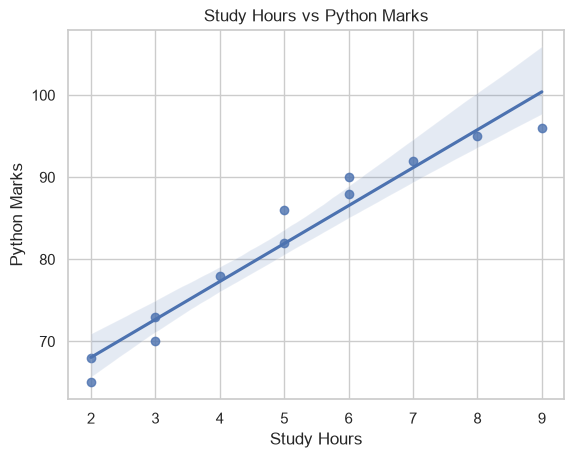

In [ ]:
# આપણે StudyHours ને X-axis પર અને Python marks ને Y-axis પર રાખીને trend તપાસીશું.

# 3. sns.regplot() — Linear Regression
# regplot() એક axes પર scatter points અને fitted regression line દર્શાવે છે.

# Scatter points અને regression line બનાવે છે
sns.regplot(
    data=df,
    x="StudyHours", # independent/explanatory
    y="Python" # dependent/response
)

plt.title("Study Hours vs Python Marks")
plt.xlabel("Study Hours")
plt.ylabel("Python Marks")
plt.show()

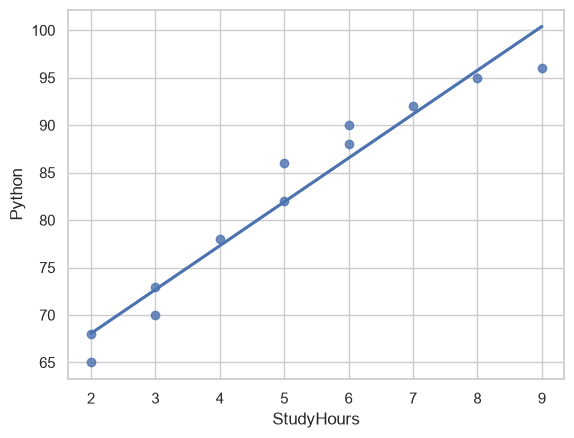

In [4]:
# Confidence interval શું છે?
# Regression line ની આસપાસ દેખાતો shaded વિસ્તાર model ની estimated mean trend માટેનો uncertainty interval દર્શાવે છે. તે raw data ના 95% points આ વિસ્તારમાં હશે એવો અર્થ નથી.

# Confidence interval છુપાવવા માટે:

sns.regplot(
    data=df,
    x="StudyHours",
    y="Python",
    ci=None
)

plt.show()

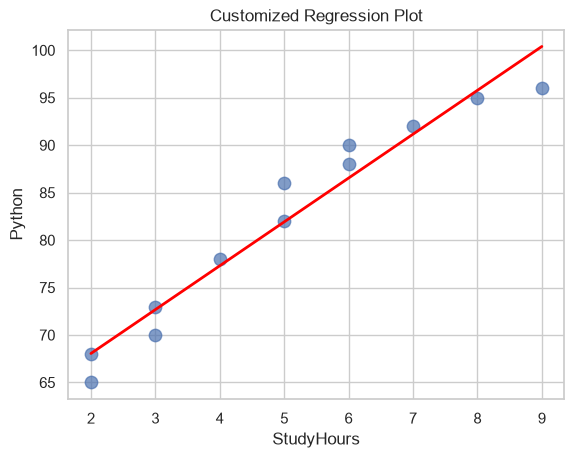

In [ ]:
# 4. Regression Line ને Customize કરવી
sns.regplot(
    data=df,
    x="StudyHours",
    y="Python",
    ci=None,
    scatter_kws={"s": 80, "alpha": 0.7}, #s { size, point: tarsparny}
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Customized Regression Plot")
plt.show()


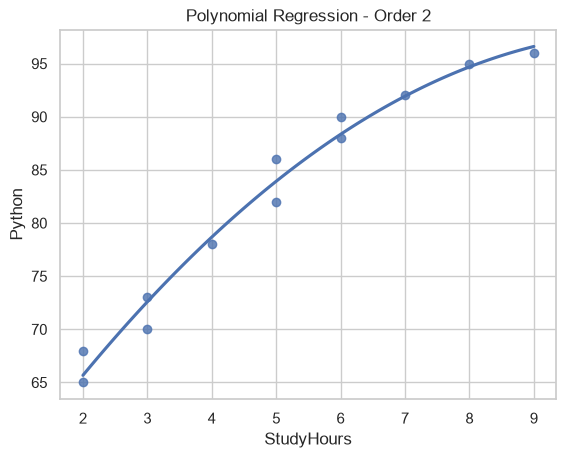

In [ ]:
# 5. order — Polynomial Trend
# દરેક dataset માટે સીધી linear line યોગ્ય હોય એવું નથી. ક્યારેક data માં curved pattern હોઈ શકે છે.

# order=2 quadratic polynomial fit કરે છે.

sns.regplot(
    data=df,
    x="StudyHours",
    y="Python",
    order=2,
    ci=None
)

plt.title("Polynomial Regression - Order 2")
plt.show()

# order=1 — સામાન્ય linear trend.
# order=2 — quadratic curve.
# order=3 — cubic polynomial curve.

# Order વધારવાથી curve વધુ જટિલ બની શકે છે અને overfitting નો જોખમ પણ વધી શકે છે. તેથી માત્ર chart વધુ સરસ દેખાય છે એટલા માટે મોટો order પસંદ ન કરવો.

In [9]:
# 6. lowess=True — Smooth Trend
# જો relationship સીધી line જેવો ન હોય તો LOWESS smoothing દ્વારા data ના સ્થાનિક pattern મુજબ smooth curve જોઈ શકાય છે.

# sns.regplot(
#     data=df,
#     x="StudyHours",
#     y="Python",
#     lowess=True,
#     ci=None
# )

# plt.title("LOWESS Smoothed Trend")
# plt.show()

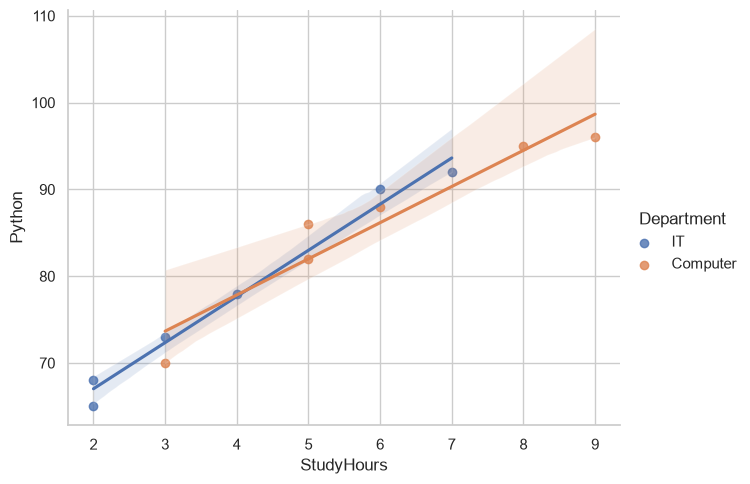

In [ ]:
# 7. sns.lmplot() — Group-wise Regression
# lmplot() પણ regression plot બનાવે છે, પરંતુ તે figure-level function છે. તેની મદદથી hue, col અને row દ્વારા groups ની સરખામણી અથવા અલગ panels બનાવી શકાય છે.
# Example 1: Department પ્રમાણે Regression

sns.lmplot(
    data=df,
    x="StudyHours",
    y="Python",
    hue="Department",
    height=5,
    aspect=1.3
)

# hue="Department" — IT અને Computer માટે અલગ રંગ અને regression fit.
# height=5 — figure ની ઊંચાઈ.
# aspect=1.3 — પહોળાઈ અને ઊંચાઈનો ratio.

plt.show()

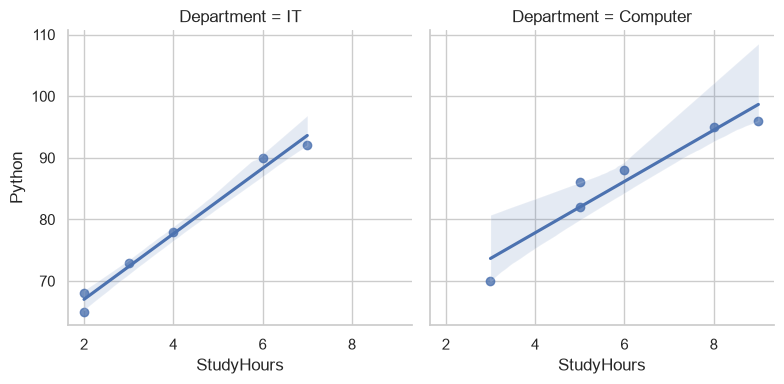

In [11]:
# Example 2: દરેક Department માટે અલગ panel
sns.lmplot(
    data=df,
    x="StudyHours",
    y="Python",
    col="Department",
    height=4,
    aspect=1.0
)

plt.show()


In [12]:
# regplot() અને lmplot() વચ્ચેનો ફરક
# Feature	regplot()	lmplot()
# પ્રકાર	Axes-level	Figure-level
# Scatter + regression	હા	હા
# hue	સીધો parameter નથી	હા
# col / row	સીધો parameter નથી	હા
# યોગ્ય ઉપયોગ	એક axes પર regression	Groups અને facets ની સરખામણી



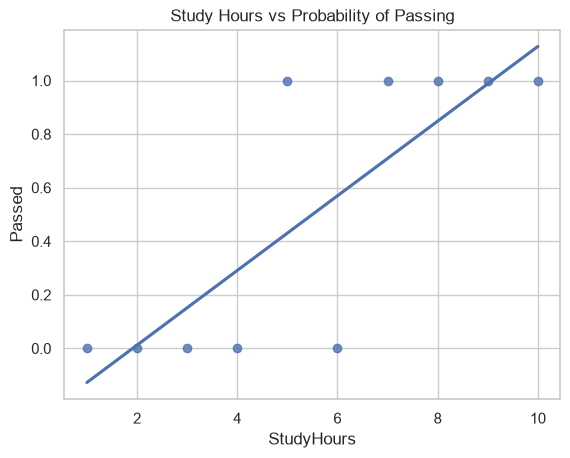

In [17]:
# 8. Logistic Regression નો પરિચય
# જો target variable numerical continuous value ના બદલે binary હોય — જેમ કે વિદ્યાર્થી પાસ થયો કે નાપાસ — તો Logistic Regression ઉપયોગી બની શકે છે.

# Seaborn માં regplot() માટે logistic=True આપીને logistic regression નો અંદાજિત curve જોઈ શકાય છે.
pass_data = {
    "StudyHours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Passed":     [0, 0, 0, 0, 1, 0, 1, 1, 1, 1]
}

pass_df = pd.DataFrame(pass_data)

sns.regplot(
    data=pass_df,
    x="StudyHours",
    y="Passed",
    logistic=False,
    ci=None
)

plt.title("Study Hours vs Probability of Passing")
plt.show()


In [18]:
# 9. કયો Regression Plot ક્યારે વાપરવો?
# પરિસ્થિતિ	યોગ્ય વિકલ્પ
# સામાન્ય linear trend	regplot()
# Confidence interval વગર line	regplot(ci=None)
# Curved polynomial trend	regplot(order=2)
# Smooth nonlinear trend	regplot(lowess=True)
# અલગ categories ની regression સરખામણી	lmplot(hue=...)
# અલગ panels માં regression	lmplot(col=...)
# Binary outcome ની probability નો trend	regplot(logistic=True)

In [ ]:
# 11. Practical Assignment
# Assignment Progress
# 0/7

# [ ] StudyHours અને Python માટે regplot બનાવો.
# [ ] ci=None સાથે confidence interval વગરનો chart બનાવો.
# [ ] order=2 વાપરીને polynomial fit જુઓ.
# [ ] lowess=True સાથે smooth trend જુઓ.
# [ ] lmplot માં hue='Department' વાપરો.
# [ ] lmplot માં col='Department' વાપરો.
# [ ] દરેક chart ના trend અને limitations વિશે 2 વાક્યો લખો.
# VS Code Notebook માં દરેક task ચલાવીને પૂર્ણ થયેલા પસંદ કરો.